# Indexing and evaluation: statistics for the report

This notebook computes all the numbers, tables and figures that we use in the report of Part 2


* Imports and load data

In [1]:
import sys
import json
import math
import time
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# root of the repository (project_progress/part_2 -> ../..), so we can import myapp
ROOT_DIR = Path('..') / '..'
sys.path.append(str(ROOT_DIR))
from project_progress.part_1.preprocess import TextPreprocessor
from indexing  import (get_doc_terms, build_inverted_index, conjunctive_search,
                                     get_term_statistics, build_tfidf_index, search_tfidf)
from evaluation import evaluate_system, precision_at_k
with open(ROOT_DIR / 'config.yaml', encoding='utf-8') as f:
    config = yaml.safe_load(f)

data_dir = ROOT_DIR / config['paths']['data_dir']
text_fields = config['indexing']['text_fields']
test_queries = config['search']['test_queries']

with open(data_dir / config['paths']['processed_dataset'], encoding='utf-8') as f:
    docs = json.load(f)

preprocessor = TextPreprocessor()
N = len(docs)
print('Number of documents:', N)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/franciscobalboa/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Number of documents: 28080


* Build the indexes (we also measure the time)

In [2]:
start = time.time()
index_plain, product_id_info = build_inverted_index(docs, text_fields)
time_plain = time.time() - start

start = time.time()
index, tf, df, idf, product_id_info = build_tfidf_index(docs, text_fields)
time_tfidf = time.time() - start

print('Time inverted index only:', round(time_plain, 2), 's')
print('Time inverted index + tf-idf:', round(time_tfidf, 2), 's')

Time inverted index only: 0.17 s
Time inverted index + tf-idf: 3.36 s


## 1.1 Building the inverted index

* Table 1: what each field contributes

In [3]:
# for each field we count the average number of tokens, the vocabulary and the empty fields
rows = []
for field in text_fields:
    total_tokens = 0
    empty = 0
    vocabulary = set()
    for doc in docs:
        tokens = doc.get(field)
        if not tokens:
            empty += 1
            continue
        total_tokens += len(tokens)
        for token in tokens:
            vocabulary.add(token)
    rows.append({'field': field,
                 'avg_tokens': round(total_tokens / N, 1),
                 'vocabulary': len(vocabulary),
                 'empty': empty,
                 'empty_%': round(100 * empty / N, 1)})

# the same for all the fields joined (this is what we index)
lengths = []
for doc in docs:
    lengths.append(len(get_doc_terms(doc, text_fields)))
rows.append({'field': 'all joined',
             'avg_tokens': round(np.mean(lengths), 1),
             'vocabulary': len(index),
             'empty': 0,
             'empty_%': 0.0})

table1 = pd.DataFrame(rows)
display(table1)
print('Document length -> median:', np.median(lengths), ' min:', min(lengths), ' max:', max(lengths))

,field,avg_tokens,vocabulary,empty,empty_%
0,processed_title,6.1,721,0,0.0
1,processed_description,18.7,4671,11150,39.7
2,processed_metadata,23.4,4005,0,0.0
3,all joined,48.2,6788,0,0.0


Document length -> median: 38.0  min: 7  max: 580


* Table 2: preprocessing steps on a real description (first product of the dataset)

In [4]:
import re

doc = docs[0]
# we only use the first sentence so the example is short
raw_text = doc['description'].split('.')[0]
print('pid:', doc['pid'])
print('0. Raw text:', raw_text)

# step 1: lowercase and remove everything that is not a letter, a digit or a space
clean_text = re.sub(r'[^a-z0-9\s]', ' ', raw_text.lower())
# step 2: tokenisation
tokens = clean_text.split()
print('1-2. Tokens:', tokens)

# step 3: remove stop words and 1-character tokens
kept = []
removed = []
for t in tokens:
    if t not in preprocessor.stop_words and len(t) > 1:
        kept.append(t)
    else:
        removed.append(t)
print('3. Without stop words:', kept)
print('   removed:', removed)

# step 4: stemming
stems = []
for t in kept:
    stems.append(preprocessor.stemmer.stem(t))
print('4. Stems:', stems)

# check that it is the same as our preprocess_text
print('Same as preprocess_text:', stems == preprocessor.preprocess_text(raw_text))

pid: TKPFCZ9EA7H5FYZH
0. Raw text: Yorker trackpants made from 100% rich combed cotton giving it a rich look
1-2. Tokens: ['yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look']
3. Without stop words: ['yorker', 'trackpants', 'made', '100', 'rich', 'combed', 'cotton', 'giving', 'rich', 'look']
   removed: ['from', 'it', 'a']
4. Stems: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look']
Same as preprocess_text: True


* Statistics of the inverted index

In [5]:
posting_lengths = []
for term in index:
    posting_lengths.append(len(index[term]))

longest_term = max(index, key=lambda t: len(index[t]))

df1 = 0
df5 = 0
more_than_half = 0
for length in posting_lengths:
    if length == 1:
        df1 += 1
    if length <= 5:
        df5 += 1
    if length > N / 2:
        more_than_half += 1

print('Vocabulary size:', len(index))
print('Total postings:', sum(posting_lengths))
print('Average posting length:', round(np.mean(posting_lengths), 1), ' median:', np.median(posting_lengths))
print('Longest posting list:', longest_term, len(index[longest_term]),
      '(' + str(round(100 * len(index[longest_term]) / N, 1)) + '%)')
print('Terms with df = 1:', df1, '(' + str(round(100 * df1 / len(index), 1)) + '%)')
print('Terms with df <= 5:', df5, '(' + str(round(100 * df5 / len(index), 1)) + '%)')
print('Terms in more than half of the products:', more_than_half)

# example of why we need the set: occurrences vs documents
total_shirt = 0
for doc in docs:
    total_shirt += get_doc_terms(doc, text_fields).count('shirt')
print('shirt -> occurrences:', total_shirt, ' documents (df):', len(index['shirt']))

Vocabulary size: 6788
Total postings: 962038
Average posting length: 141.7  median: 5.0
Longest posting list: wear 20971 (74.7%)
Terms with df = 1: 1930 (28.4%)
Terms with df <= 5: 3562 (52.5%)
Terms in more than half of the products: 11
shirt -> occurrences: 50038  documents (df): 16770


* AND search step by step (query: men black leather jacket)

In [6]:
query = 'men black leather jacket'
query_terms = preprocessor.preprocess_text(query)

result = None
for term in query_terms:
    term_docs = set(index[term])
    if result is None:
        result = term_docs
    else:
        result = result.intersection(term_docs)
    print(term, '-> df:', len(term_docs), ' candidates after intersection:', len(result))

men -> df: 14250  candidates after intersection: 14250
black -> df: 6317  candidates after intersection: 3463
leather -> df: 281  candidates after intersection: 66
jacket -> df: 1110  candidates after intersection: 7


## 1.2 Test queries

* Statistics of every term (tf_total, df, idf) and df per field

In [7]:
stats = pd.DataFrame(get_term_statistics(docs, index, text_fields))
# get_term_statistics uses the natural log, in the report we use base 2 (like in the ranking)
stats['idf2'] = np.log2(N / stats['df']).round(3)
stats['tf_idf2'] = (stats['tf_total'] * stats['idf2']).round(0)

# df of each term in each field separately
field_df = {}
for field in text_fields:
    field_df[field] = Counter()
    for doc in docs:
        tokens = doc.get(field)
        if not tokens:
            continue
        for t in set(tokens):
            field_df[field][t] += 1

stats['df_title'] = stats['term'].map(lambda t: field_df['processed_title'][t])
stats['df_description'] = stats['term'].map(lambda t: field_df['processed_description'][t])
stats['df_metadata'] = stats['term'].map(lambda t: field_df['processed_metadata'][t])
stats['%_products'] = (100 * stats['df'] / N).round(1)

# step 1: most frequent terms
display(stats.sort_values('df', ascending=False).head(10)[
    ['term', 'tf_total', 'df', '%_products', 'idf2', 'df_title', 'df_description', 'df_metadata']])

/var/folders/b7/phk426_j58j5ljqbf83gv69m0000gn/T/ipykernel_95508/1720361524.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  stats['idf2'] = np.log2(N / stats['df']).round(3)
/var/folders/b7/phk426_j58j5ljqbf83gv69m0000gn/T/ipykernel_9550

,term,tf_total,df,%_products,idf2,df_title,df_description,df_metadata
145,wear,31691,20971,74.7,0.421,16,5416,19506
48,wash,26834,20528,73.1,0.452,107,2142,19935
11,cotton,34079,19918,70.9,0.495,1647,7248,19094
333,western,19189,19118,68.1,0.555,1,67,19074
332,sleev,26262,18034,64.2,0.639,2030,3330,17985
262,shirt,50038,16770,59.7,0.744,15838,8503,11239
47,machin,17958,15760,56.1,0.833,0,1081,15554
84,regular,27447,15397,54.8,0.867,1754,1456,14787
369,topwear,15315,15310,54.5,0.875,0,0,15310
165,neck,42259,14586,51.9,0.945,11952,2534,14417


In [8]:
# step 2: long tail
print('Terms with df <= 5:', (stats['df'] <= 5).sum())

# step 3: medium band 300 <= df <= 3000 ranked by collection tf-idf
band = stats[(stats['df'] >= 300) & (stats['df'] <= 3000)].sort_values('tf_idf2', ascending=False)
band = band.reset_index(drop=True)
band.index = band.index + 1
print('Terms in the band:', len(band))
display(band.head(30)[['term', 'tf_total', 'df', 'tf_idf2']])

Terms with df <= 5: 3562
Terms in the band: 445


,term,tf_total,df,tf_idf2
1,kurta,4202,1196,19132.0
2,jacket,3338,1110,15558.0
3,sweatshirt,3558,1418,15328.0
4,sock,2812,692,15025.0
5,jean,4257,2436,15014.0
6,tshirt,4009,2648,13659.0
7,graphic,3288,1770,13113.0
8,green,3449,2083,12944.0
9,stripe,3029,1464,12910.0
10,pant,3378,2069,12711.0


* Figure 1: in which field appears each query term

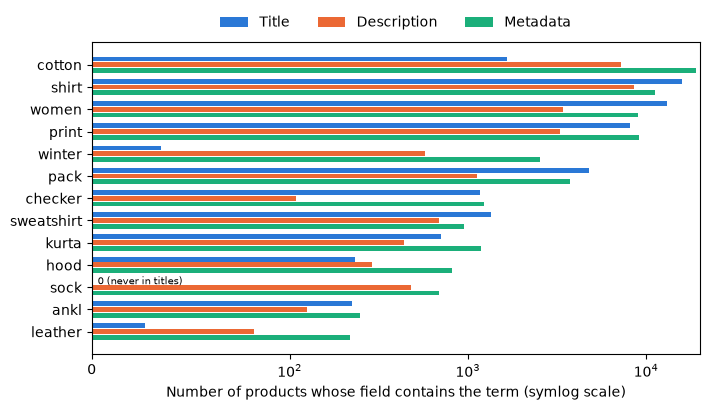

In [9]:
fig_terms = ['cotton', 'shirt', 'women', 'print', 'winter', 'pack', 'checker',
             'sweatshirt', 'kurta', 'hood', 'sock', 'ankl', 'leather']
sub = stats.set_index('term').loc[fig_terms]

fig, ax = plt.subplots(figsize=(7.2, 4.2))
y = np.arange(len(fig_terms))
h = 0.26
ax.barh(y - h, sub['df_title'], height=h - 0.04, color='#2a78d6', label='Title')
ax.barh(y, sub['df_description'], height=h - 0.04, color='#eb6834', label='Description')
ax.barh(y + h, sub['df_metadata'], height=h - 0.04, color='#1baf7a', label='Metadata')
ax.set_yticks(y)
ax.set_yticklabels(fig_terms)
ax.invert_yaxis()
ax.set_xscale('symlog', linthresh=100)
ax.set_xlabel('Number of products whose field contains the term (symlog scale)')
ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0))
for i in range(len(fig_terms)):
    if sub['df_title'].iloc[i] == 0:
        ax.text(3, i - h, '0 (never in titles)', va='center', fontsize=7)
plt.tight_layout()
plt.show()

* Table 3: df, idf and P(modifier | head) of the terms of our queries

In [10]:
# head (product type) of each of our queries
heads = {
    'women cotton printed kurta': 'kurta',
    'men black leather jacket': 'jacket',
    'men slim fit formal checkered shirt': 'checker',
    'women hooded winter sweatshirt': 'sweatshirt',
    'cotton ankle socks pack': 'sock',
}

rows = []
for query in test_queries:
    query_terms = preprocessor.preprocess_text(query)
    head = heads[query]
    head_docs = set(index[head])
    n_results = len(conjunctive_search(query_terms, index))
    for term in query_terms:
        # share of the products of the head that also contain the modifier
        if term == head:
            p_mod = 'head'
        else:
            p_mod = round(len(head_docs & set(index[term])) / len(head_docs), 3)
        rows.append({'query': query, 'term': term, 'df': df[term],
                     'idf2': round(math.log2(N / df[term]), 2),
                     'P(mod|head)': p_mod, 'AND results': n_results})

display(pd.DataFrame(rows))

,query,term,df,idf2,P(mod|head),AND results
0,women cotton printed kurta,women,13807,1.02,0.508,42
1,women cotton printed kurta,cotton,19918,0.50,0.949,42
2,women cotton printed kurta,print,9859,1.51,0.055,42
3,women cotton printed kurta,kurta,1196,4.55,head,42
4,men black leather jacket,men,14250,0.98,0.502,7
5,men black leather jacket,black,6317,2.15,0.268,7
6,men black leather jacket,leather,281,6.64,0.05,7
7,men black leather jacket,jacket,1110,4.66,head,7
8,men slim fit formal checkered shirt,men,14250,0.98,0.5,32
9,men slim fit formal checkered shirt,slim,5679,2.31,0.492,32


## 1.3 Ranking with TF-IDF

* Table 4: score of the first result of Q2 term by term

In [11]:
query = 'men black leather jacket'
query_terms = preprocessor.preprocess_text(query)
ranked = search_tfidf(query, preprocessor, index, tf, idf)
top_pid = ranked[0][1]

doc_terms = get_doc_terms(product_id_info[top_pid], text_fields)
counts = Counter(doc_terms)
# norm of the sublinear tf vector of the document
norm = 0
for t in counts:
    norm += (1 + math.log2(counts[t])) ** 2
norm = math.sqrt(norm)
print(product_id_info[top_pid]['title'], '| terms:', len(doc_terms), ' distinct:', len(counts), ' norm:', round(norm, 3))

# query: every term appears once -> weight 1, norm sqrt(4) = 2
query_norm = math.sqrt(len(query_terms))
rows = []
total = 0
for term in query_terms:
    f = counts[term]
    w = 1 + math.log2(f)
    j = index[term].index(top_pid)  # position of the product in the posting list
    q = (1 / query_norm) * idf[term]
    contribution = q * tf[term][j] * idf[term]
    total += contribution
    rows.append({'term': term, 'f': f, 'w': round(w, 3), 'tf': tf[term][j], 'idf': idf[term],
                 'q': round(q, 3), 'contribution': round(contribution, 3)})
display(pd.DataFrame(rows))
print('Score by hand:', round(total, 3), ' score of search_tfidf:', round(float(ranked[0][0]), 3))
print('Second result score:', round(float(ranked[1][0]), 3))

Full Sleeve Color Block, Applique Men Leather Jacket | terms: 38  distinct: 27  norm: 7.705


,term,f,w,tf,idf,q,contribution
0,men,2,2.000,0.2596,0.9786,0.489,0.124
1,black,1,1.000,0.1298,2.1522,1.076,0.301
2,leather,3,2.585,0.3355,6.6428,3.321,7.402
3,jacket,3,2.585,0.3355,4.6609,2.330,3.644


Score by hand: 11.471  score of search_tfidf: 11.471
Second result score: 8.539


* Table 5: top-3 results of each query

In [12]:
for query in test_queries:
    ranked = search_tfidf(query, preprocessor, index, tf, idf)
    print('\n' + query, '->', len(ranked), 'results')
    for position in range(3):
        score = ranked[position][0]
        pid = ranked[position][1]
        print(position + 1, round(score, 3), pid, product_id_info[pid]['title'])


women cotton printed kurta -> 42 results
1 4.634 KTAFZCK5XEZCZXF8 Women Printed Cotton Linen Blend Straight Kurta  (Beige)
2 4.634 KTAFZCK5RGNECHHH Women Printed Cotton Linen Blend Straight Kurta  (Blue)
3 4.634 KTAFZCH5954HZSWJ Women Printed Cotton Linen Blend Straight Kurta  (White)

men black leather jacket -> 7 results
1 11.471 JCKFAYVDVBJJSU2K Full Sleeve Color Block, Applique Men Leather Jacket
2 8.539 JCKF7FHYECSZGCQA Full Sleeve Solid Men Quilted Jacket
3 8.193 JCKENCYBCG6RZYYS Full Sleeve Solid Men Jacket

men slim fit formal checkered shirt -> 32 results
1 5.293 SHTFYVTPWXWTZXSN Men Slim Fit Checkered Formal Shirt
2 4.889 SHTFDYSQZ9AG7ZTV Men Slim Fit Checkered Button Down Collar Formal Shirt
3 4.85 SHTFW52ZRF2MGWFE Men Slim Fit Checkered Spread Collar Formal Shirt

women hooded winter sweatshirt -> 252 results
1 8.415 SWSFXZWGMGVDUCXA Full Sleeve Printed Women Sweatshirt
2 8.351 SWSFXZWWCSGRZ3HT Full Sleeve Solid Women Sweatshirt
3 8.351 SWSFXZWRDFRAWMN2 Full Sleeve Solid W

* Comparison with the raw tf of the lab (top-10 overlap)

In [13]:
# raw tf normalized by the euclidean norm, like in the lab
raw_tf = defaultdict(list)
for doc in docs:
    counts = Counter(get_doc_terms(doc, text_fields))
    norm = 0
    for t in counts:
        norm += counts[t] ** 2
    norm = math.sqrt(norm)
    for t in counts:
        raw_tf[t].append(counts[t] / norm)

def rank_raw(query_terms, candidates):
    # same as rank_documents but with the raw tf
    query_counts = Counter(query_terms)
    terms = list(query_counts.keys())
    query_norm = 0
    for t in terms:
        query_norm += query_counts[t] ** 2
    query_norm = math.sqrt(query_norm)
    query_vector = []
    for t in terms:
        query_vector.append(query_counts[t] / query_norm * idf[t])
    doc_vectors = defaultdict(lambda: [0] * len(terms))
    for i in range(len(terms)):
        t = terms[i]
        for j in range(len(index[t])):
            pid = index[t][j]
            if pid in candidates:
                doc_vectors[pid][i] = raw_tf[t][j] * idf[t]
    scores = []
    for pid in doc_vectors:
        scores.append([np.dot(query_vector, doc_vectors[pid]), pid])
    scores.sort(reverse=True)
    return scores

for query in test_queries:
    query_terms = preprocessor.preprocess_text(query)
    candidates = conjunctive_search(query_terms, index)
    top_sub = []
    for s, pid in search_tfidf(query, preprocessor, index, tf, idf)[:10]:
        top_sub.append(pid)
    top_raw = []
    for s, pid in rank_raw(query_terms, candidates)[:10]:
        top_raw.append(pid)
    print(query, '-> common in top 10:', len(set(top_sub) & set(top_raw)),
          '| same first result:', top_sub[0] == top_raw[0])

women cotton printed kurta -> common in top 10: 4 | same first result: False
men black leather jacket -> common in top 10: 7 | same first result: True
men slim fit formal checkered shirt -> common in top 10: 9 | same first result: True
women hooded winter sweatshirt -> common in top 10: 8 | same first result: True
cotton ankle socks pack -> common in top 10: 2 | same first result: True


## 2. Evaluation on the validation queries

* Metrics at K = 10 (only the products with a label are evaluated)

In [14]:
labels = pd.read_csv(data_dir / config['paths']['validation_labels'])
validation_queries = config['evaluation']['validation_queries']

results = evaluate_system(validation_queries, labels, index, tf, idf, preprocessor, k=10)
for q_idx, query_text, metrics in results['query_metrics']:
    print(q_idx, query_text, metrics)
print('MAP@10:', results['MAP'], ' MRR@10:', results['MRR'])

1 women full sleeve sweatshirt cotton {'P@K': 1.0, 'R@K': 0.769, 'F1@K': 0.87, 'AP@K': 1.0, 'RR@K': 1.0, 'NDCG@K': 1.0}
2 men slim jeans blue {'P@K': 0.6, 'R@K': 0.6, 'F1@K': 0.6, 'AP@K': 0.948, 'RR@K': 1.0, 'NDCG@K': 0.716}
MAP@10: 0.974  MRR@10: 1.0


* Table 8: labels in ranking order and judged products excluded by the AND

In [15]:
for q_idx in range(1, len(validation_queries) + 1):
    query = validation_queries[q_idx - 1]
    query_labels = labels[labels['query_id'] == q_idx]
    rel_map = dict(zip(query_labels['pid'], query_labels['labels']))
    query_terms = preprocessor.preprocess_text(query)

    ranked = search_tfidf(query, preprocessor, index, tf, idf)
    order = []
    retrieved = set()
    for score, pid in ranked:
        if pid in rel_map:
            order.append(rel_map[pid])
            retrieved.add(pid)

    print('\nQ' + str(q_idx), query)
    print('  relevant in csv:', int(query_labels['labels'].sum()))
    print('  judged products that pass the AND:', len(retrieved), 'of', len(query_labels))
    print('  labels in ranking order:', order)

    # which judged products are lost in the AND step and why
    for _, row in query_labels.iterrows():
        if row['pid'] not in retrieved:
            doc_terms = set(get_doc_terms(product_id_info[row['pid']], text_fields))
            missing = []
            for t in query_terms:
                if t not in doc_terms:
                    missing.append(t)
            print('  excluded:', row['title'], '| label:', row['labels'], '| missing terms:', missing)


Q1 women full sleeve sweatshirt cotton
  relevant in csv: 13
  judged products that pass the AND: 20 of 20
  labels in ranking order: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0]

Q2 men slim jeans blue
  relevant in csv: 10
  judged products that pass the AND: 8 of 20
  labels in ranking order: [1, 1, 1, 1, 0, 1, 1, 0]
  excluded: Super Skinny Women Blue Jeans | label: 0 | missing terms: ['men']
  excluded: Slim Women Blue Jeans | label: 1 | missing terms: ['men']
  excluded: Super Skinny Women Blue Jeans | label: 1 | missing terms: ['men']
  excluded: Slim Women Blue Jeans | label: 0 | missing terms: ['men']
  excluded: Slim Women Blue Jeans | label: 0 | missing terms: ['men']
  excluded: Super Skinny Women Blue Jeans | label: 0 | missing terms: ['men']
  excluded: Slim Women Dark Blue Jeans | label: 0 | missing terms: ['men']
  excluded: Tapered Fit Men Blue Jeans | label: 1 | missing terms: ['slim']
  excluded: Super Skinny Women Blue Jeans | label: 1 | missing ter